<a href="https://colab.research.google.com/github/jindalritik-error/rj-student-performance-analysis-numpy/blob/main/Student_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/MakroMB/student-performance-analysis/main/data/student-por.csv"

df = pd.read_csv(url, sep=";")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [18]:
grades = df["G3"].to_numpy()

print("Total Students:", len(grades))
print("Average Grade:", np.mean(grades))
print("Highest Grade:", np.max(grades))
print("Lowest Grade:", np.min(grades))
print("Median Grade:", np.median(grades))
print("Standard Deviation:", np.std(grades))

Total Students: 649
Average Grade: 11.906009244992296
Highest Grade: 19
Lowest Grade: 0
Median Grade: 12.0
Standard Deviation: 3.2281663339626148


In [19]:
# Grade categories
fail = np.sum(grades < 10)
average = np.sum((grades >= 10) & (grades < 15))
good = np.sum((grades >= 15) & (grades < 18))
excellent = np.sum(grades >= 18)

print("Below 10:", fail)
print("10 to 14:", average)
print("15 to 17:", good)
print("18 to 20:", excellent)

Below 10: 100
10 to 14: 418
15 to 17: 114
18 to 20: 17


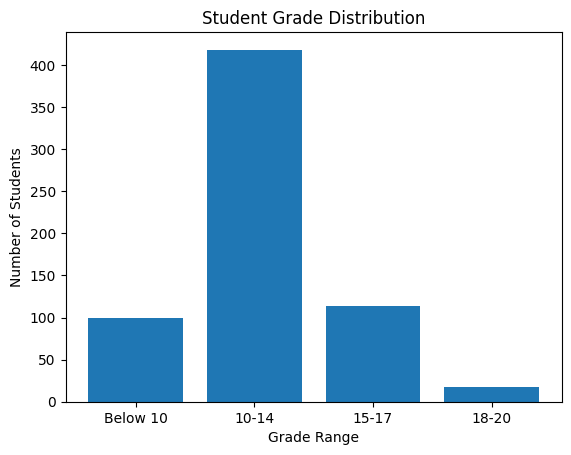

In [20]:
categories = ["Below 10", "10-14", "15-17", "18-20"]
counts = [fail, average, good, excellent]

plt.bar(categories, counts)
plt.title("Student Grade Distribution")
plt.xlabel("Grade Range")
plt.ylabel("Number of Students")
plt.show()

In [21]:
study_time = df["studytime"].to_numpy()

for hours in np.unique(study_time):
    student_grades = grades[study_time == hours]

    print(
        "Study Time Category:", hours,
        "| Students:", len(student_grades),
        "| Average Grade:", np.mean(student_grades)
    )

Study Time Category: 1 | Students: 212 | Average Grade: 10.84433962264151
Study Time Category: 2 | Students: 305 | Average Grade: 12.091803278688525
Study Time Category: 3 | Students: 97 | Average Grade: 13.22680412371134
Study Time Category: 4 | Students: 35 | Average Grade: 13.057142857142857


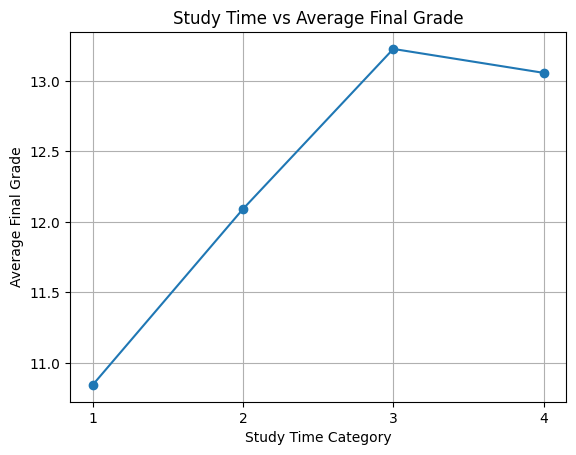

In [22]:
study_categories = np.unique(study_time)

avg_grades = [
    np.mean(grades[study_time == category])
    for category in study_categories
]

plt.plot(study_categories, avg_grades, marker="o")
plt.title("Study Time vs Average Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")
plt.xticks([1, 2, 3, 4])
plt.grid()
plt.show()

In [23]:
total_students = len(grades)

passed = np.sum(grades >= 10)
failed = np.sum(grades < 10)

pass_percentage = (passed / total_students) * 100
fail_percentage = (failed / total_students) * 100

print("Total Students:", total_students)
print("Passed Students:", passed)
print("Failed Students:", failed)
print("Pass Percentage:", pass_percentage)
print("Fail Percentage:", fail_percentage)

Total Students: 649
Passed Students: 549
Failed Students: 100
Pass Percentage: 84.59167950693374
Fail Percentage: 15.408320493066254


In [24]:
# Sort grades in ascending order
sorted_grades = np.sort(grades)

print("Lowest 10 Grades:", sorted_grades[:10])
print("Highest 10 Grades:", sorted_grades[-10:][::-1])

Lowest 10 Grades: [0 0 0 0 0 0 0 0 0 0]
Highest 10 Grades: [19 19 18 18 18 18 18 18 18 18]


In [25]:
# Find indexes of top 10 students
top_indexes = np.argsort(grades)[-10:][::-1]

print("Top 10 Grades:", grades[top_indexes])

Top 10 Grades: [19 19 18 18 18 18 18 18 18 18]


In [26]:
print("25th Percentile:", np.percentile(grades, 25))
print("50th Percentile:", np.percentile(grades, 50))
print("75th Percentile:", np.percentile(grades, 75))
print("90th Percentile:", np.percentile(grades, 90))

25th Percentile: 10.0
50th Percentile: 12.0
75th Percentile: 14.0
90th Percentile: 16.0


In [27]:
variance = np.var(grades)

print("Grade Variance:", variance)
print("Grade Standard Deviation:", np.std(grades))
print("Grade Range:", np.max(grades) - np.min(grades))

Grade Variance: 10.421057879729629
Grade Standard Deviation: 3.2281663339626148
Grade Range: 19


In [28]:
# Variance and range
print("Variance:", np.var(grades))
print("Standard Deviation:", np.std(grades))
print("Grade Range:", np.ptp(grades))

# Unique grades and their frequencies
unique_grades, counts = np.unique(grades, return_counts=True)

print("\nGrade Frequency:")
for grade, count in zip(unique_grades, counts):
    print(grade, ":", count)

# Students above and below average
average_grade = np.mean(grades)

above_average = grades[grades > average_grade]
below_average = grades[grades < average_grade]

print("\nAbove Average Students:", len(above_average))
print("Below Average Students:", len(below_average))

Variance: 10.421057879729629
Standard Deviation: 3.2281663339626148
Grade Range: 19

Grade Frequency:
0 : 15
1 : 1
5 : 1
6 : 3
7 : 10
8 : 35
9 : 35
10 : 97
11 : 104
12 : 72
13 : 82
14 : 63
15 : 49
16 : 36
17 : 29
18 : 15
19 : 2

Above Average Students: 348
Below Average Students: 301


In [29]:
print("========== STUDENT PERFORMANCE REPORT ==========")

print("Total Students:", len(grades))
print("Average Grade:", np.mean(grades))
print("Median Grade:", np.median(grades))
print("Highest Grade:", np.max(grades))
print("Lowest Grade:", np.min(grades))

print("Pass Percentage:", (np.sum(grades >= 10) / len(grades)) * 100)

print("Grade Variance:", np.var(grades))
print("Grade Standard Deviation:", np.std(grades))

print("================================================")

========== STUDENT PERFORMANCE REPORT ==========
Total Students: 649
Average Grade: 11.906009244992296
Median Grade: 12.0
Highest Grade: 19
Lowest Grade: 0
Pass Percentage: 84.59167950693374
Grade Variance: 10.421057879729629
Grade Standard Deviation: 3.2281663339626148


### **Project Conclusion**
1.Dataset contains 649 student records.

2.Average final grade and median grade were calculated using NumPy.

3.Highest and lowest grades were identified.

4.Pass percentage was approximately 84.59%.

5.Grade distribution was analyzed using NumPy.

6.Study time and final grade relationship was explored.

7.Percentile, variance and standard deviation were calculated.